# S&P 500 Pairs Trading with Cointegration

## 1. Research question

Can formation-period cointegration identify stock pairs whose
subsequent mean reversion generates profits after trading costs?

I evaluate parameter sensitivity, relationship stability, and
portfolio-level risk and return.

| Period | Dates | Purpose |
| --- | --- | --- |
| Formation | 2018–2021 | Screen pairs and estimate spread models |
| Validation | 2022–2023 | Select trading parameters |
| Test | 2024 | Evaluate the frozen portfolio configuration |

The test period was inspected during development.
Results are a retrospective evaluation.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

audit = pd.read_csv(
    ROOT / "data/processed/formation_price_audit.csv",
    index_col=0,
)

coverage = audit["status"].value_counts().rename_axis("status").to_frame("securities")

display(coverage)
assert len(audit) == 505
assert audit["included"].sum() == 407

,securities
status,
included,407
no_valid_prices,96
incomplete_history,2


## 2. Universe and data quality

The December 29, 2017 historical membership snapshot contains
505 securities. The saved adjusted-price data provide complete,
positive, finite formation-period observations for 407 securities.

The remaining 98 securities include 96 with no valid formation
prices and two with incomplete histories. Exclusion decisions
use formation-period coverage only.

The resulting matrix contains 1,008 dates and 407 securities,
yielding 82,621 unique pairs.

Missing histories and ticker changes limit coverage and can
introduce selection bias. Historical membership is based on
a community-maintained reconstruction.

## 3. Cointegration screening

For each pair, I regress the first stock's log price on an intercept
and the second stock's log price. Ticker order is fixed alphabetically.

The Engle–Granger test evaluates the null hypothesis of no
cointegration. The residual test uses zero augmentation lags.

I test all 82,621 pairs using formation-period data. Because many
hypotheses are tested, I also apply the Benjamini–Hochberg procedure
at a 5% false discovery rate target.

Passing this screen provides formation-period evidence.
Subsequent spread recovery and profitability require separate evaluation.

In [3]:
screen = pd.read_csv(ROOT / "outputs/cointegration_screen.csv")

summary = pd.DataFrame({
    "screen": ["All pairs", "Raw p < 0.05", "BH-adjusted p < 0.05"],
    "count": [
        len(screen),
        screen["passes_raw_5pct"].sum(),
        screen["passes_bh_5pct"].sum(),
    ],
})
display(summary)

candidates = (
    screen.loc[screen["passes_bh_5pct"]]
    .sort_values("p_value")
    .reset_index(drop=True)
)

display(
    candidates[
        ["ticker_a", "ticker_b", "p_value", "bh_adjusted_p"]
    ].style.format({
        "p_value": "{:.3e}",
        "bh_adjusted_p": "{:.4f}",
    })
)

assert len(screen) == 82_621
assert len(candidates) == 16

,screen,count
0,All pairs,82621
1,Raw p < 0.05,7165
2,BH-adjusted p < 0.05,16


,ticker_a,ticker_b,p_value,bh_adjusted_p
0,CFG,MGM,9.560e-08,0.0079
1,ARE,EW,6.587e-07,0.0272
2,AKAM,EQIX,1.181e-06,0.0319
3,ADI,EL,1.543e-06,0.0319
4,D,KMB,2.352e-06,0.0325
5,BA,NCLH,2.362e-06,0.0325
6,BF-B,FMC,4.003e-06,0.0440
7,ARE,ZTS,4.264e-06,0.0440
8,D,WEC,5.615e-06,0.0499
9,HST,KSS,8.043e-06,0.0499


## 4. Cointegration across periods

I retain the 16 formation-period candidates and repeat the
Engle–Granger test separately in validation and test data.

Each test re-estimates the relationship within its own period.
These are retrospective diagnostics. They do not change the
formation-selected trading universe.

The periods have different sample lengths, which can affect
statistical power. Failure to reject the null does not establish
that a relationship is absent.

In [4]:
stability = pd.read_csv(ROOT / "outputs/pair_stability.csv")

p_values = stability.pivot(
    index=["ticker_a", "ticker_b"],
    columns="period",
    values="p_value",
)

comparison = (
    candidates.set_index(["ticker_a", "ticker_b"])[["p_value"]]
    .rename(columns={"p_value": "Formation"})
    .join(p_values)
    [["Formation", "Validation", "Test"]]
)

display(comparison.style.format("{:.3e}"))

counts = pd.DataFrame({
    "pairs_tested": comparison.notna().sum(),
    "raw_p_below_0.05": comparison.lt(0.05).sum(),
})
display(counts)

,,Formation,Validation,Test
ticker_a,ticker_b,,,
CFG,MGM,9.560e-08,6.535e-01,1.229e-01
ARE,EW,6.587e-07,5.254e-01,5.517e-01
AKAM,EQIX,1.181e-06,7.765e-01,5.284e-01
ADI,EL,1.543e-06,1.699e-01,1.816e-01
D,KMB,2.352e-06,9.258e-01,4.249e-01
BA,NCLH,2.362e-06,8.783e-01,3.552e-02
BF-B,FMC,4.003e-06,8.072e-02,9.077e-01
ARE,ZTS,4.264e-06,7.580e-01,6.274e-01
D,WEC,5.615e-06,4.954e-01,3.922e-01


,pairs_tested,raw_p_below_0.05
Formation,16,16
Validation,16,0
Test,16,1


None of the 16 candidates passed the raw 5% threshold in validation;
one passed in the test period. Formation-period evidence did not
consistently recur in later periods.

The one test-period rejection is unadjusted for multiple testing.
The formation results are conditional on having selected these
pairs for strong formation evidence.

I therefore evaluate the trading rules directly, including
holding limits, costs, and portfolio losses.

## 5. Spread construction and trading signals

For the first formation-ranked candidate, CFG–MGM, I estimate

s_t = log(P_CFG,t) − alpha − beta × log(P_MGM,t).

The intercept, hedge ratio, spread mean, and spread standard
deviation are estimated over 2018–2021 and then frozen.

The z-score measures the spread's distance from its formation
mean in formation-period standard deviations.

The figure shows reference entry bands of ±2 and exit bands
of ±0.5. These illustrate the initial rule; parameter selection
is reported in a later section.

The dashed vertical line marks the start of validation in 2022.
The dotted vertical line marks the start of the test period in 2024.

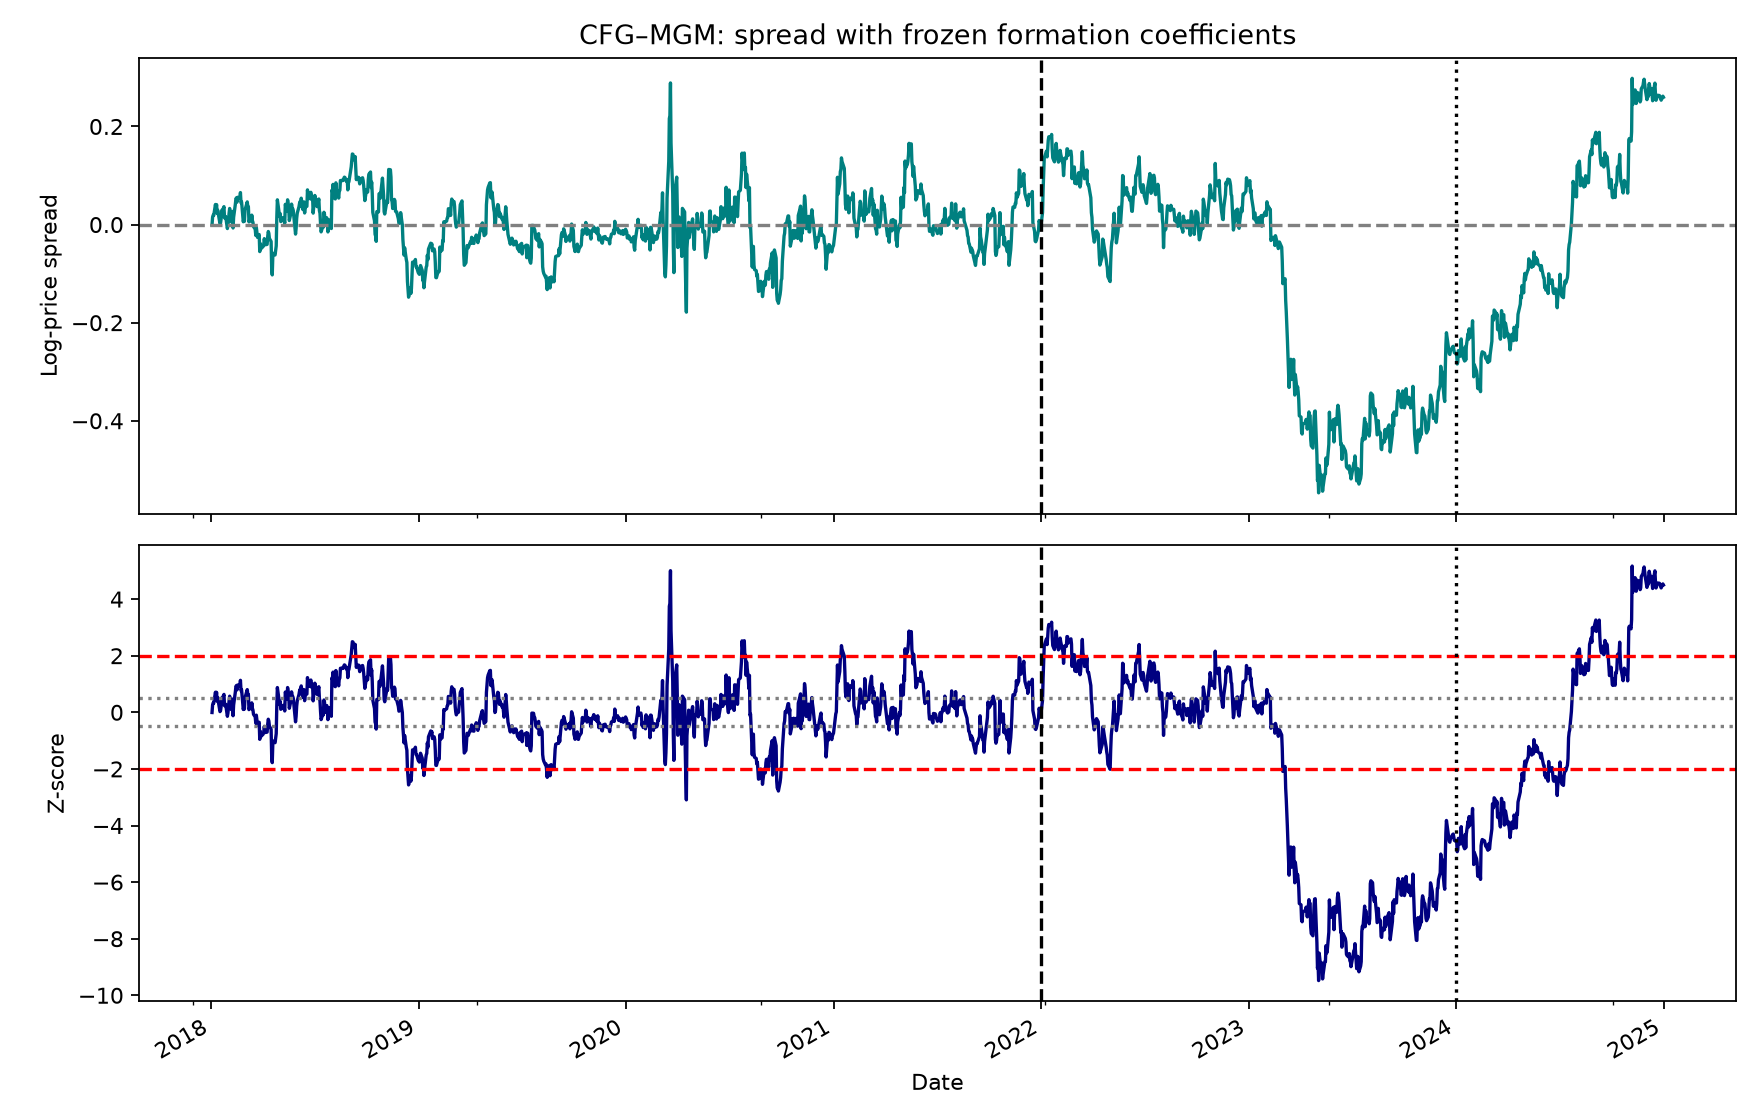

In [5]:
from IPython.display import Image

display(Image(
    filename=str(ROOT / "outputs/selected_pair_spread.png"),
    width=950,
))

A short-spread signal occurs when z crosses upward through +2.
A long-spread signal occurs when z crosses downward through −2.
A position becomes eligible for exit when |z| ≤ 0.5.

Signals use closing prices, and orders execute at the following
trading day's close. The execution z-score can therefore differ
from the value that triggered the order.

Persistent departures from zero suggest that the frozen historical
relationship requires scrutiny. A large z-score alone does not
establish that the spread will revert.

## 6. Execution and trade accounting

The initial CFG–MGM strategy uses entry bands of ±2 and exit
bands of ±0.5. It has no holding-period limit or stop loss.
Any open position is liquidated at the period end.

Each entry has $10,000 of gross exposure. For hedge ratio beta,
the two legs receive absolute dollar amounts proportional to
1 and |beta|. Shares remain fixed until exit.

Gross P&L for each leg equals signed shares multiplied by the
change in price. Each opening and closing fill incurs 5 basis
points on its traded value.

Execution is approximated using adjusted closing prices.
Fractional shares are allowed. Borrow fees, financing costs,
and market impact are omitted.

In [6]:
trade_log = pd.read_csv(
    ROOT / "outputs/validation_trade_log.csv",
    parse_dates=["entry_date", "exit_date"],
)

display(trade_log.style.format({
    "entry_date": lambda value: value.strftime("%Y-%m-%d"),
    "exit_date": lambda value: value.strftime("%Y-%m-%d"),
    "gross_pnl": "${:,.2f}",
    "fees": "${:,.2f}",
    "net_pnl": "${:,.2f}",
}))

total_pnl = trade_log["net_pnl"].sum()
win_rate = trade_log["net_pnl"].gt(0).mean()

print(f"Completed trades: {len(trade_log)}")
print(f"Total net P&L: ${total_pnl:,.2f}")
print(f"Win rate: {win_rate:.0%}")

,entry_date,exit_date,direction,exit_reason,gross_pnl,fees,net_pnl
0,2022-01-07,2022-03-31,-1,signal,$630.27,$9.43,$620.84
1,2022-05-03,2022-05-10,1,signal,$341.23,$9.67,$331.56
2,2022-06-22,2022-07-29,-1,signal,$616.22,$10.56,$605.66
3,2022-11-04,2022-11-15,-1,signal,$425.41,$10.26,$415.15
4,2023-03-03,2023-12-29,1,period_end,$-743.40,$9.51,$-752.91


Completed trades: 5
Total net P&L: $1,220.29
Win rate: 80%


The first trade ran from January 7 to March 31, 2022.
The short CFG leg earned approximately $885.00, while the
long MGM leg lost $254.73. After $9.43 in fees, net P&L was $620.84.

The final trade remained open from March 3 to December 29, 2023,
and lost $752.91 after fees. This loss offset about 38% of the
preceding four trades' combined profits.

The 80% win rate therefore needs to be read alongside trade
sizes, holding durations, and losses.

## 7. Account equity and risk

The account starts with $10,000. Daily equity includes realized
and unrealized P&L, with fees deducted when trades execute.

Drawdown measures the percentage decline from the highest
account value reached up to that date.

Returns use the previous day's account equity as the denominator.
Annualization assumes 252 trading days per year. Sharpe uses
a zero risk-free rate.

,Metric,Value
0,Total return,12.20%
1,Annualized return,5.96%
2,Annualized volatility,12.33%
3,Maximum drawdown,-16.73%
4,Annualized Sharpe,0.531


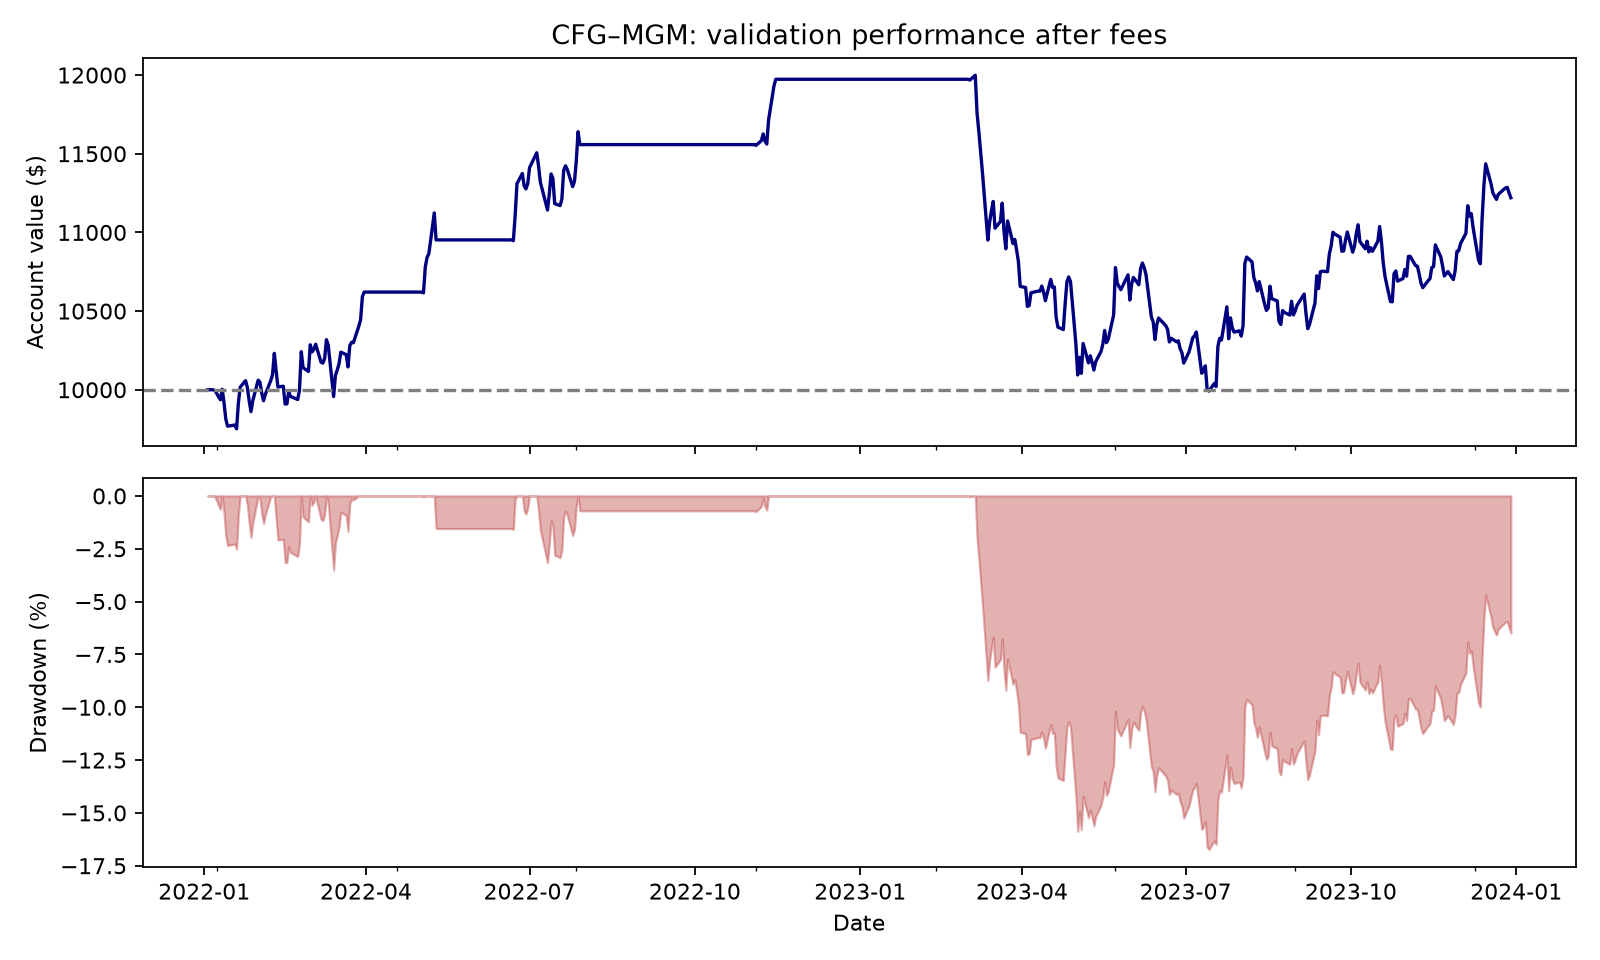

In [7]:
import numpy as np

account = pd.read_csv(
    ROOT / "outputs/validation_equity.csv",
    index_col=0,
    parse_dates=True,
)

initial_capital = 10_000.0
equity = account["equity"]
previous_equity = equity.shift(1).fillna(initial_capital)
daily_returns = equity / previous_equity - 1

total_return = equity.iloc[-1] / initial_capital - 1
annual_return = (
    equity.iloc[-1] / initial_capital
) ** (252 / len(equity)) - 1

daily_sd = daily_returns.std(ddof=1)
annual_volatility = daily_sd * np.sqrt(252)
sharpe = (
    daily_returns.mean() / daily_sd * np.sqrt(252)
    if daily_sd > 0 else np.nan
)

drawdown = equity / equity.cummax().clip(lower=initial_capital) - 1

metrics = pd.DataFrame({
    "Metric": [
        "Total return",
        "Annualized return",
        "Annualized volatility",
        "Maximum drawdown",
        "Annualized Sharpe",
    ],
    "Value": [
        f"{total_return:.2%}",
        f"{annual_return:.2%}",
        f"{annual_volatility:.2%}",
        f"{drawdown.min():.2%}",
        f"{sharpe:.3f}",
    ],
})

assert np.isclose(
    equity.iloc[-1] - initial_capital,
    trade_log["net_pnl"].sum(),
)

display(metrics)
display(Image(
    filename=str(ROOT / "outputs/validation_performance.png"),
    width=950,
))

The account earned 12.20% over validation, but experienced a
16.73% peak-to-trough drawdown. The final long-held position
accounted for the pronounced decline during 2023.

The ending profit alone understates the losses experienced
during the holding period. This motivates testing holding
limits and stop-loss rules on validation data.

## 8. Parameter sensitivity on validation data

I first explore CFG–MGM over 2022–2023. Formation-period prices
determine the hedge ratio and spread normalization.

I compare holding limits, entry and exit thresholds, stop losses,
trading costs, and estimation windows. These sequential experiments
help explain individual effects; they do not constitute a joint
search over every parameter combination.

Portfolio-level selection is evaluated separately in the next section.

In [8]:
single_grid = pd.read_csv(
    ROOT / "outputs/validation_parameter_grid.csv"
)

eligible = single_grid.loc[
    single_grid["trades"].ge(5)
    & np.isfinite(single_grid["sharpe"])
]
top_configs = eligible.sort_values(
    "sharpe", ascending=False, kind="stable"
).head(5)

display(top_configs[
    ["max_days", "entry_z", "exit_z", "trades",
     "total_return", "max_drawdown", "sharpe"]
].style.format({
    "total_return": "{:.2%}",
    "max_drawdown": "{:.2%}",
    "sharpe": "{:.3f}",
}))

thresholds = pd.read_csv(
    ROOT / "outputs/threshold_comparison.csv"
)
display(
    thresholds.pivot(
        index="entry_z",
        columns="exit_z",
        values="sharpe",
    ).style.format("{:.3f}")
)

,max_days,entry_z,exit_z,trades,total_return,max_drawdown,sharpe
10,10,1.500000,0.250000,10,15.90%,-8.67%,1.024
11,10,1.500000,0.500000,10,15.65%,-8.68%,1.009
9,10,1.500000,0.000000,10,15.66%,-8.35%,1.000
1,Unlimited,1.500000,0.250000,7,25.10%,-15.39%,0.990
28,60,1.500000,0.250000,7,20.16%,-14.63%,0.982


exit_z,0.000000,0.250000,0.500000
entry_z,,,
1.500000,0.824,0.881,0.769
2.000000,0.568,0.513,0.331
2.500000,-0.563,-0.563,-0.563


In [9]:
experiments = {
    "Stop-loss comparison": "validation_stop_comparison.csv",
    "Transaction-cost comparison": "validation_cost_comparison.csv",
    "Estimation-window comparison": "validation_lookback_comparison.csv",
}

for title, filename in experiments.items():
    print(title)
    table = pd.read_csv(ROOT / "outputs" / filename)
    display(table.round(4))

Stop-loss comparison


,max_days,trades,net_pnl,total_return,max_drawdown,sharpe,stop_loss
0,10,10,1590.3504,0.1590,-0.0867,1.0236,NaN
1,10,10,2006.0264,0.2006,-0.0428,1.3639,0.03
2,10,10,1629.5621,0.1630,-0.0867,1.0590,0.06


Transaction-cost comparison


,max_days,trades,net_pnl,total_return,max_drawdown,sharpe,fee_bps_per_fill
0,10,10,2105.5873,0.2106,-0.0413,1.4282,0
1,10,10,2006.0264,0.2006,-0.0428,1.3639,5
2,10,10,1906.4655,0.1906,-0.0443,1.2989,10
3,10,10,1707.3437,0.1707,-0.0473,1.1672,20


Estimation-window comparison


,max_days,trades,net_pnl,total_return,max_drawdown,sharpe,lookback,hedge_ratio,intercept,spread_mean,spread_sd
0,10,7,123.6883,0.0124,-0.0686,0.1305,126,0.5675,1.4863,0.0,0.0406
1,10,8,475.0820,0.0475,-0.0638,0.4061,252,0.5930,1.3980,0.0,0.0440
2,10,9,1496.5071,0.1497,-0.0446,1.1082,504,0.7814,0.6852,-0.0,0.0601
3,10,10,2006.0264,0.2006,-0.0428,1.3639,1008,0.7810,0.6841,-0.0,0.0577


For CFG–MGM, the 36-configuration search selected entry at 1.5,
exit at 0.25, and a ten-day holding limit by validation Sharpe.

With those settings fixed, a 3% stop improved validation Sharpe
from 1.024 to 1.364. Increasing costs reduced performance.
Among the tested estimation windows, the full 1,008-day window
performed best under the selected execution settings.

These findings are conditional on this pair, period, and search.
The number of attempted configurations creates selection optimism.
The five-trade eligibility rule provides only a minimal activity filter.

## 9. Portfolio construction and validation

Each of the 16 formation-selected pairs receives $10,000,
giving total initial capital of $160,000. Uninvested cash
earns zero.

Each trade uses $10,000 of gross exposure. Pair sleeves are
accounted for separately, including when they share a stock.
Orders across sleeves are not netted.

I first apply the CFG–MGM settings to every pair. I then compare
27 portfolio configurations across holding limits and entry/exit
thresholds, keeping the 3% stop and 5-basis-point fill cost fixed.
Selection uses portfolio validation Sharpe.

In [10]:
contributions = pd.read_csv(
    ROOT / "outputs/validation_pair_contributions.csv"
)

display(
    contributions.sort_values("net_pnl", ascending=False)
    .style.format({"net_pnl": "${:,.2f}"})
)

initial_portfolio = 10_000 * len(contributions)
print(
    "Portfolio return using CFG–MGM settings:",
    f"{contributions['net_pnl'].sum() / initial_portfolio:.2%}",
)

,Unnamed: 0,pair,trades,net_pnl
0,0,CFG-MGM,10,"$2,006.03"
1,2,AKAM-EQIX,10,"$1,445.86"
2,12,DHI-ITW,13,"$1,382.09"
3,9,HST-KSS,5,"$1,060.27"
4,11,PEG-YUM,10,$837.52
5,10,BKNG-MGM,12,$90.16
6,15,EW-PEP,3,$-254.90
7,8,D-WEC,4,$-314.70
8,14,BKNG-CFG,9,$-373.73
9,7,ARE-ZTS,9,$-594.65


Portfolio return using CFG–MGM settings: -1.61%


In [11]:
portfolio_grid = pd.read_csv(
    ROOT / "outputs/portfolio_threshold_grid.csv"
)

portfolio_ranked = portfolio_grid.loc[
    portfolio_grid["trades"].ge(5)
    & np.isfinite(portfolio_grid["sharpe"])
].sort_values("sharpe", ascending=False, kind="stable")

display(
    portfolio_ranked.head(5).style.format({
        "total_return": "{:.2%}",
        "max_drawdown": "{:.2%}",
        "sharpe": "{:.3f}",
    })
)

,max_days,entry_z,exit_z,trades,total_return,max_drawdown,sharpe
22,60,2.000000,0.250000,71,3.98%,-1.71%,0.971
5,10,2.000000,0.500000,106,2.72%,-1.84%,0.872
4,10,2.000000,0.250000,106,2.71%,-1.81%,0.867
3,10,2.000000,0.000000,106,2.63%,-1.86%,0.836
21,60,2.000000,0.000000,72,3.05%,-1.90%,0.735


Applying the CFG–MGM settings to all 16 pairs produced a
validation return of −1.61%. Performance on one selected pair
did not generalize across the portfolio.

The portfolio search selected entry at 2.0, exit at 0.25,
and a 60-day holding limit. It generated 71 trades, a 3.98%
validation return, a maximum drawdown of 1.71%, and Sharpe of 0.971.

These parameters were frozen for the subsequent 2024 evaluation.
The search optimized portfolio Sharpe, calculated from the
aggregate daily equity curve.

## 10. Frozen portfolio evaluation in 2024

I retain all 16 formation-selected pairs and apply the portfolio
validation winner: entry at 2.0, exit at 0.25, a 60-day holding
limit, and a 3% stop. Each fill costs 5 basis points.

Formation-period coefficients and normalization remain frozen.
The test starts with each sleeve flat and funded with $10,000.

The 2024 period was inspected during development, so this
evaluation is retrospective.

In [12]:
test_metrics = pd.read_csv(ROOT / "outputs/portfolio_test_metrics.csv")
test_contributions = pd.read_csv(
    ROOT / "outputs/portfolio_test_contributions.csv"
)
test_sleeves = pd.read_csv(
    ROOT / "outputs/portfolio_test_pair_equities.csv",
    index_col=0,
    parse_dates=True,
)

test_initial = 10_000 * test_sleeves.shape[1]
test_equity = test_sleeves.sum(axis=1)

assert np.isclose(
    test_equity.iloc[-1] - test_initial,
    test_contributions["net_pnl"].sum(),
)

display(test_metrics.style.format({
    "total_return": "{:.6%}",
    "max_drawdown": "{:.2%}",
    "sharpe": "{:.3f}",
}))

display(
    test_contributions.sort_values("net_pnl", ascending=False)
    .style.format({"net_pnl": "${:,.2f}"})
)

,max_days,entry_z,exit_z,trades,total_return,max_drawdown,sharpe
0,60,2.000000,0.250000,16,-0.000632%,-1.34%,0.007


,pair,trades,net_pnl
6,BF-B-FMC,2,$986.14
13,DTE-YUM,3,$654.66
5,BA-NCLH,2,$268.93
3,ADI-EL,0,$0.00
4,D-KMB,0,$0.00
7,ARE-ZTS,0,$0.00
8,D-WEC,0,$0.00
9,HST-KSS,0,$0.00
10,BKNG-MGM,0,$0.00
14,BKNG-CFG,0,$0.00


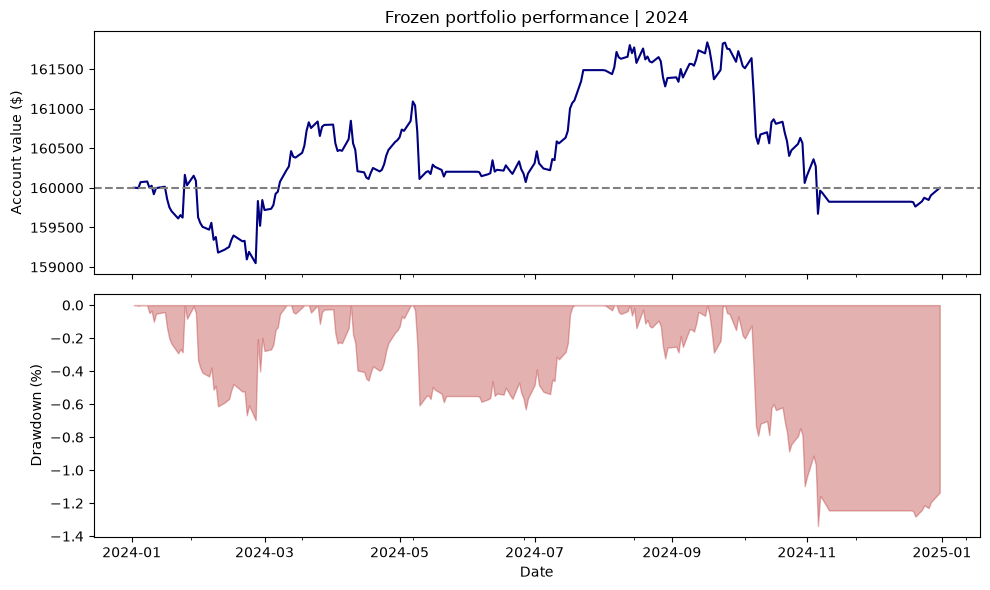

In [13]:
import matplotlib.pyplot as plt

test_drawdown = (
    test_equity / test_equity.cummax().clip(lower=test_initial) - 1
)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

test_equity.plot(ax=axes[0], color="navy")
axes[0].axhline(test_initial, color="gray", linestyle="--")
axes[0].set_title("Frozen portfolio performance | 2024")
axes[0].set_ylabel("Account value ($)")

axes[1].fill_between(
    test_drawdown.index,
    100 * test_drawdown.to_numpy(),
    0,
    color="firebrick",
    alpha=0.35,
)
axes[1].set_ylabel("Drawdown (%)")
axes[1].set_xlabel("Date")

fig.tight_layout()
fig.savefig(ROOT / "outputs/portfolio_test_performance.png", dpi=160)
plt.show()

The portfolio completed 16 trades and finished approximately
$1.01 below its $160,000 initial capital. Maximum drawdown
was 1.34%, and annualized Sharpe was approximately 0.007.

Eight pairs traded. Three generated positive net P&L and five
generated losses, almost exactly offsetting each other.
The other eight sleeves held cash throughout the year.

The validation Sharpe of 0.971 did not persist in 2024.
This outcome motivates examining why half the candidates
generated no trades.

## 11. Why eight pairs generated no trades

Entry requires a crossing from inside the threshold to outside it.
A spread already far outside the band can remain there without
generating an entry.

I examine first and last z-scores, days outside the entry bands,
and entry crossings for each inactive pair.

In [14]:
diagnostics = pd.read_csv(ROOT / "outputs/test_signal_diagnostics.csv")
inactive = diagnostics.loc[diagnostics["trades"].eq(0)]

display(inactive.style.format({
    "first_z": "{:.2f}",
    "last_z": "{:.2f}",
}))

assert len(inactive) == 8
assert inactive["entry_crossings"].eq(0).all()
assert inactive["days_outside_entry"].eq(len(test_sleeves)).all()

,pair,first_z,last_z,days_outside_entry,entry_crossings,trades
3,ADI-EL,14.93,26.40,252,0,0
4,D-KMB,-8.38,-6.26,252,0,0
7,ARE-ZTS,-7.65,-10.81,252,0,0
8,D-WEC,-9.78,-7.21,252,0,0
9,HST-KSS,7.32,10.24,252,0,0
10,BKNG-MGM,7.22,16.19,252,0,0
14,BKNG-CFG,9.54,13.20,252,0,0
15,EW-PEP,-7.47,-5.67,252,0,0


All eight inactive pairs remained outside the entry bands
throughout the 252 trading dates in 2024.

For example, ADI–EL started near z = 14.93 and ended near
z = 26.40. These values use the frozen formation-period scale.
They do not imply normal-tail probabilities or guarantee reversal.

The inactivity reflects the crossing-based rule. Persistent
deviations also raise questions about the continued usefulness
of the formation-period price relationship.

Refitting models or changing entry rules would define a new
strategy and require a separate evaluation.

In [15]:
ledger = pd.read_csv(
    ROOT / "outputs/portfolio_test_trades.csv",
    parse_dates=["entry_date", "exit_date"],
)
trade_metrics = pd.read_csv(
    ROOT / "outputs/portfolio_test_trade_metrics.csv"
)

display(trade_metrics.style.format({
    "win_rate": "{:.2%}",
    "average_trade_return": "{:.6%}",
    "total_fees": "${:,.2f}",
    "annualized_turnover": "{:.3f}",
}))

cost_breakdown = pd.DataFrame({
    "Measure": ["Gross P&L", "Trading fees", "Net P&L"],
    "Dollars": [
        ledger["gross_pnl"].sum(),
        ledger["fees"].sum(),
        ledger["net_pnl"].sum(),
    ],
})
display(cost_breakdown.style.format({"Dollars": "${:,.2f}"}))

display(ledger[
    ["ticker_a", "ticker_b", "entry_date", "exit_date",
     "holding_days", "gross_pnl", "fees", "net_pnl"]
].round({"gross_pnl": 2, "fees": 2, "net_pnl": 2}))

,trades,win_rate,average_trade_return,total_fees,annualized_turnover
0,16,43.75%,-0.000632%,$161.12,2.014


,Measure,Dollars
0,Gross P&L,$160.11
1,Trading fees,$161.12
2,Net P&L,$-1.01


,ticker_a,ticker_b,entry_date,exit_date,holding_days,gross_pnl,fees,net_pnl
0,CFG,MGM,2024-06-06,2024-07-23,31,954.74,10.88,943.85
1,CFG,MGM,2024-08-02,2024-08-29,19,-259.91,10.37,-270.28
2,CFG,MGM,2024-10-14,2024-11-06,17,-1023.18,10.21,-1033.39
3,ARE,EW,2024-01-04,2024-02-01,19,-430.09,10.06,-440.15
4,ARE,EW,2024-08-12,2024-11-05,60,122.74,10.13,112.61
5,AKAM,EQIX,2024-02-16,2024-05-13,59,-473.90,9.41,-483.32
6,BA,NCLH,2024-01-18,2024-03-12,37,1247.33,9.82,1237.51
7,BA,NCLH,2024-09-16,2024-10-10,18,-958.46,10.12,-968.58
8,BF-B,FMC,2024-03-20,2024-05-09,35,665.39,9.92,655.46
9,BF-B,FMC,2024-12-20,2024-12-31,6,340.42,9.74,330.68


The 2024 portfolio completed 16 trades, of which seven were profitable.
Gross P&L was approximately $160.11, while trading fees totaled
$161.12, leaving a small net loss.

Annualized turnover was 2.014, defined as total entry and exit
notional divided by initial portfolio capital and elapsed trading years.

Average trade return uses each trade's initial gross exposure
as its denominator. The small gross profit was fully consumed
by modeled transaction costs.

In [16]:
def portfolio_metrics(sleeves):
    """Calculate account-level performance using daily marked equity."""
    initial = 10_000 * sleeves.shape[1]
    equity = sleeves.sum(axis=1)
    daily_returns = equity / equity.shift(1).fillna(initial) - 1
    years = len(equity) / 252
    daily_sd = daily_returns.std(ddof=1)
    peak = equity.cummax().clip(lower=initial)

    return {
        "Trading days": len(equity),
        "Total return": equity.iloc[-1] / initial - 1,
        "Annualized return": (equity.iloc[-1] / initial) ** (1 / years) - 1,
        "Annualized volatility": daily_sd * np.sqrt(252),
        "Sharpe": (
            daily_returns.mean() / daily_sd * np.sqrt(252)
            if daily_sd > 0 else np.nan
        ),
        "Maximum drawdown": (equity / peak - 1).min(),
    }


validation_sleeves = pd.read_csv(
    ROOT / "outputs/portfolio_selected_validation_equities.csv",
    index_col=0,
    parse_dates=True,
)
test_sleeves = pd.read_csv(
    ROOT / "outputs/portfolio_test_pair_equities.csv",
    index_col=0,
    parse_dates=True,
)

comparison = pd.DataFrame({
    "Validation 2022–2023": portfolio_metrics(validation_sleeves),
    "Test 2024": portfolio_metrics(test_sleeves),
}).T

comparison.to_csv(ROOT / "outputs/portfolio_period_comparison.csv")

display(comparison.style.format({
    "Trading days": "{:.0f}",
    "Total return": "{:.6%}",
    "Annualized return": "{:.4%}",
    "Annualized volatility": "{:.2%}",
    "Sharpe": "{:.3f}",
    "Maximum drawdown": "{:.2%}",
}))

,Trading days,Total return,Annualized return,Annualized volatility,Sharpe,Maximum drawdown
Validation 2022–2023,501,3.976147%,1.9806%,2.04%,0.971,-1.71%
Test 2024,252,-0.000632%,-0.0006%,1.46%,0.007,-1.34%


The validation and test portfolios use identical selected trading
parameters and start each evaluation period flat.

Validation performance reflects parameter selection on that period.
The subsequent test provides a retrospective assessment of transfer.

Annualized returns account for the different period lengths.
Sharpe assumes a zero risk-free rate and uses square-root-of-time
annualization.

In [17]:
fixed_costs = pd.read_csv(
    ROOT / "outputs/portfolio_fixed_trade_costs.csv"
)
rerun_costs = pd.read_csv(
    ROOT / "outputs/portfolio_test_cost_sensitivity.csv"
)

cost_comparison = fixed_costs[
    ["fee_bps", "net_pnl"]
].rename(columns={"net_pnl": "Fixed executions"})

cost_comparison = cost_comparison.merge(
    rerun_costs[["fee_bps", "net_pnl"]].rename(
        columns={"net_pnl": "Strategy rerun"}
    ),
    on="fee_bps",
    validate="one_to_one",
)

display(cost_comparison.style.format({
    "Fixed executions": "${:,.2f}",
    "Strategy rerun": "${:,.2f}",
}))

,fee_bps,Fixed executions,Strategy rerun
0,0,$160.11,$160.11
1,5,$-1.01,$-1.01
2,10,$-162.13,$-162.13
3,20,$-484.37,"$1,142.78"


### Transaction costs and stop-loss execution

Holding executions fixed, increasing fill costs reduces net P&L.
The approximately $160.11 gross profit breaks even at about
4.97 basis points per fill.

Rerunning the strategy at 20 basis points changes exit dates
because the stop-loss condition includes fees. Earlier exits
in BA–NCLH, CFG–MGM, and PEG–YUM reduced subsequent losses
in this historical sample.

This improvement depends on the altered trading path.
It does not establish that higher transaction costs improve
expected performance.

The 3% stop is evaluated at the close and executed at the next
close. Realized losses can therefore exceed the trigger amount.

In [18]:
screen = pd.read_csv(ROOT / "outputs/cointegration_screen.csv")

cutoff_rows = []

for cutoff in [0.01, 0.05, 0.10]:
    selected = screen.loc[screen["bh_adjusted_p"] < cutoff]
    stocks = set(selected["ticker_a"]) | set(selected["ticker_b"])

    cutoff_rows.append({
        "bh_cutoff": cutoff,
        "selected_pairs": len(selected),
        "distinct_stocks": len(stocks),
    })

cutoff_summary = pd.DataFrame(cutoff_rows)
display(cutoff_summary)

cutoff_summary.to_csv(
    ROOT / "outputs/cointegration_cutoff_summary.csv",
    index=False,
)

,bh_cutoff,selected_pairs,distinct_stocks
0,0.01,1,2
1,0.05,16,25
2,0.10,55,72


### Cointegration threshold sensitivity

I compare BH-adjusted thresholds of 0.01, 0.05, and 0.10
using the same formation-period test results.

A wider threshold admits more pairs and may increase
diversification or introduce weaker relationships.
Shared stocks can create overlapping portfolio exposures.

Portfolio performance must be compared at equal total initial
capital. The threshold will be evaluated on validation data.

In [19]:
cutoff_performance = pd.read_csv(
    ROOT / "outputs/validation_cutoff_performance.csv"
)

display(cutoff_performance.style.format({
    "bh_cutoff": "{:.2f}",
    "capital_per_pair": "${:,.2f}",
    "total_return": "{:.2%}",
    "max_drawdown": "{:.2%}",
    "sharpe": "{:.3f}",
}))

strict_pair = screen.loc[
    screen["bh_adjusted_p"] < 0.01,
    ["ticker_a", "ticker_b", "bh_adjusted_p"],
]
display(strict_pair)

,bh_cutoff,pairs,capital_per_pair,trades,total_return,max_drawdown,sharpe
0,0.01,1,"$160,000.00",5,20.57%,-3.91%,1.372
1,0.05,16,"$10,000.00",71,3.98%,-1.71%,0.971
2,0.10,55,"$2,909.09",229,2.37%,-1.50%,0.727


,ticker_a,ticker_b,bh_adjusted_p
0,CFG,MGM,0.007899


At equal total initial capital, the 1% BH threshold produced
the highest validation Sharpe under the fixed trading rules.
However, it selected only one pair and generated five trades.

Wider thresholds admitted more pairs and reduced maximum
drawdown, while also reducing returns and Sharpe in this sample.

This comparison holds execution parameters fixed. It does not
establish a general relationship between cointegration p-values
and future profitability.

In [20]:
lookback_performance = pd.read_csv(
    ROOT / "outputs/portfolio_lookback_comparison.csv"
)

display(lookback_performance.style.format({
    "total_return": "{:.2%}",
    "max_drawdown": "{:.2%}",
    "sharpe": "{:.3f}",
}))

,lookback,pairs,trades,total_return,max_drawdown,sharpe
0,126,16,108,-3.66%,-4.84%,-0.838
1,252,16,92,-4.60%,-6.17%,-1.069
2,504,16,77,1.68%,-2.04%,0.432
3,1008,16,71,3.98%,-1.71%,0.971


### Portfolio estimation-window sensitivity

With the 16-pair universe and execution rules fixed, the full
1,008-day formation window achieved the highest validation Sharpe.

Shorter windows generated more trades but lower returns.
This comparison changes the fitted hedge ratio and spread
normalization together. It does not isolate their individual effects.

The models remain frozen throughout validation. Rolling
re-estimation is a separate strategy design.

In [21]:
stop_comparison = pd.read_csv(
    ROOT / "outputs/portfolio_stop_comparison.csv",
    keep_default_na=False,
)

display(stop_comparison.style.format({
    "total_return": "{:.2%}",
    "max_drawdown": "{:.2%}",
    "sharpe": "{:.3f}",
}))

,stop_loss,trades,total_return,max_drawdown,sharpe
0,None,61,8.76%,-3.00%,1.494
1,3%,71,3.98%,-1.71%,0.971
2,6%,65,6.50%,-2.05%,1.297


### Portfolio stop-loss sensitivity

With all other settings fixed, removing the stop increased
validation return from 3.98% to 8.76% and Sharpe from 0.971
to 1.494. Maximum drawdown increased from 1.71% to 3.00%.

The 3% stop reduced drawdown but also reduced return and Sharpe.
Its favorable result on CFG–MGM did not transfer to the full
portfolio under these settings.

The no-stop strategy still exits on mean reversion, the 60-day
holding limit, or the period end.

In [22]:
joint_grid = pd.read_csv(
    ROOT / "outputs/joint_validation_grid.csv",
    keep_default_na=False,
)
joint_winner = pd.read_csv(
    ROOT / "outputs/joint_validation_winner.csv",
    keep_default_na=False,
)
joint_test = pd.read_csv(
    ROOT / "outputs/joint_winner_test_metrics.csv"
)

display(joint_winner[
    ["bh_cutoff", "lookback", "max_days",
     "entry_z", "exit_z", "stop_loss", "pairs"]
])

columns = ["trades", "total_return", "max_drawdown", "sharpe"]

joint_comparison = pd.DataFrame(
    [
        joint_winner.iloc[0][columns].to_dict(),
        joint_test.iloc[0][columns].to_dict(),
    ],
    index=["Validation 2022–2023", "Test 2024"],
)

display(joint_comparison.style.format({
    "trades": "{:.0f}",
    "total_return": "{:.2%}",
    "max_drawdown": "{:.2%}",
    "sharpe": "{:.3f}",
}))

,bh_cutoff,lookback,max_days,entry_z,exit_z,stop_loss,pairs
0,0.01,1008,60,1.5,0.5,0.03,1


,trades,total_return,max_drawdown,sharpe
Validation 2022–2023,8,27.25%,-4.04%,1.592
Test 2024,4,-12.09%,-13.26%,-1.383


## Joint parameter search

I evaluated 972 validation configurations across the BH cutoff,
estimation window, entry and exit thresholds, holding limit,
and stop loss. Eligible configurations required at least five
completed trades and were ranked by portfolio Sharpe.

The winner selected only CFG–MGM. It earned 27.25% with Sharpe
1.592 in validation, then lost 12.09% with Sharpe −1.384 in 2024.

The result illustrates weak transfer of the validation winner.
The broad parameter search, small trade count, and concentration
in one pair limit confidence in its apparent validation advantage.

The 2024 period had already been examined during development.
This is a retrospective evaluation, and fresh data are needed
for an independent assessment.

## Main evaluation results

The initial search fixed the universe at 16 pairs and compared
27 execution configurations. Its winner earned 3.98% in
validation and approximately zero in 2024.

The broader 972-configuration search also varied the screening
cutoff, estimation window, and stop loss. Its winner selected
one pair, earned 27.25% in validation, and lost 12.09% in 2024.

Both evaluations used dates already inspected during development.

## 12. Conclusions and limitations

The study screened 82,621 S&P 500 pairs and retained 16 after
formation-period BH correction. Later cointegration tests
provided limited evidence of persistence.

Parameter choices materially affected trading results.
Settings selected on one pair did not transfer well to the
portfolio. The portfolio validation winner subsequently
earned approximately zero in 2024.

The results depend on historical price coverage, frozen models,
fixed trade notionals, and approximate execution. Shared stocks
create overlapping exposures. Borrow fees, financing costs,
and market impact remain unmodeled.

Further work includes broader parameter validation, more realistic
execution costs, and evaluation on fresh data.